# Real Data Inference with NPE

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pickle
import h5py
from tqdm import tqdm

from omegaconf import OmegaConf
from pathlib import Path

from sbi import utils as utils
from sbi import analysis as analysis
from sbi.inference.posteriors import DirectPosterior

import sys

project_root = Path.cwd().resolve().parent if Path.cwd().name == "analysis" else Path.cwd().resolve()
src_dir = project_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from priors import generate_posterior_prior_from_config, generate_fret_prior_from_config
from utils import eval_free_energy_from_config, eval_force_from_config
from utils import map_with_cached_embedding

/home/dingeldein/Venvs/fret_sbi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration

In [23]:
# Trained model path
cfg_path = "/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/exp_8/2026-05-05/11-20-02/"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Experimental data
DATA_ROOT = Path("/home/dingeldein/Desktop/fret_sbi/data_ben_schuler/Sturzenegger_transition_path_data")
CONDITION_INDEX = 2 # ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi (base condition)
seed = 11

# Observation settings
n_observations = 50

# Posterior sampling
num_posterior_samples = 5000
posterior_batch_size = 1000

# MAP estimation
map_num_iter = 2000
map_learning_rate = 0.0005

## Load Model, Prior, and Config

In [24]:
data_cfg_path = cfg_path + "data_config.yaml"

prior_posterior = generate_posterior_prior_from_config(data_cfg_path, device=device)
eval_force = eval_force_from_config(data_cfg_path)
eval_free_energy = eval_free_energy_from_config(data_cfg_path)
data_cfg = OmegaConf.load(data_cfg_path)

num_knots = data_cfg.prior.num_knots
theta_dim = num_knots + 2  # [logD, g_0..g_{n-1}, R0]

# Extract simulator timing from config
sim_bin_width_ms = data_cfg.simulator.time_step * data_cfg.simulator.saving_frequency
L_max_bins = data_cfg.simulator.binding.L_max_bins

print(f"Model expects: (n_obs, {L_max_bins}, 3) at {sim_bin_width_ms} ms bin width")
print(f"Posterior dimensionality: {theta_dim} = 1 (logD) + {num_knots} (knots) + 1 (R0)")

# Load density estimator
try:
    with open(cfg_path + "npe_set_estimator.pkl", "rb") as f:
        density_estimator = pickle.load(f)
except FileNotFoundError:
    with open(cfg_path + "last_npe_set_estimator.pkl", "rb") as f:
        density_estimator = pickle.load(f)

density_estimator = density_estimator.to(device)
density_estimator.eval()
print("Density estimator loaded.")

Model expects: (n_obs, 4300, 3) at 0.005 ms bin width
Posterior dimensionality: 9 = 1 (logD) + 7 (knots) + 1 (R0)
Density estimator loaded.


## Data Loading and Transformation

Load photon-by-photon HDF5 data and transform into the tensor format the NPE model expects:
- Bin photons at the simulator's native resolution (`sim_bin_width_ms`)
- Pad/truncate to `L_max_bins`
- Add binary mask channel (1 = valid, 0 = padding)

In [25]:
ACCEPTOR_ID = 1
DONOR_ID = 2


def get_trajectory_data(traj_file):
    """Load a single trajectory from an HDF5 file."""
    with h5py.File(traj_file, "r") as f:
        detector = f["Detectors"][:]
        interphoton_ds = f["InterPhotonTimes"]
        interphoton_times = interphoton_ds[:]
        macro_time_unit_ps = interphoton_ds.attrs["MacroTimeUnitInPicoSeconds"]
    return interphoton_times, macro_time_unit_ps, detector


def photons_to_model_input(interphoton_times, macro_time_unit_ps, detector,
                           sim_bin_width_ms, L_max_bins):
    """Bin photon arrivals at simulator resolution and format as model input.

    Returns
    -------
    tensor : torch.Tensor, shape (L_max_bins, 3)
        Channels: [donor_counts, acceptor_counts, mask].
    n_valid_bins : int
        Number of bins with actual data (before padding).
    """
    bin_width_ps = np.int64(sim_bin_width_ms * 1e9)  # ms -> ps
    macro_time_unit_ps = np.int64(macro_time_unit_ps)

    interphoton_times_ps = interphoton_times.astype(np.int64) * macro_time_unit_ps
    photon_times_ps = np.cumsum(interphoton_times_ps, dtype=np.int64)

    total_time_ps = photon_times_ps[-1]
    n_bins = max(1, int(np.ceil(total_time_ps / bin_width_ps)))

    # Truncate or keep as-is
    n_valid = min(n_bins, L_max_bins)
    bin_edges = np.linspace(0, n_valid * bin_width_ps, n_valid + 1)

    donor_counts, _ = np.histogram(photon_times_ps[detector == DONOR_ID], bins=bin_edges)
    acceptor_counts, _ = np.histogram(photon_times_ps[detector == ACCEPTOR_ID], bins=bin_edges)

    # Build (L_max_bins, 3) tensor: [donor, acceptor, mask]
    out = torch.zeros(L_max_bins, 3, dtype=torch.float32)
    out[:n_valid, 0] = torch.from_numpy(donor_counts.astype(np.float32))
    out[:n_valid, 1] = torch.from_numpy(acceptor_counts.astype(np.float32))
    out[:n_valid, 2] = 1.0  # mask

    return out, n_valid

In [26]:
# Excise photons around E ~ 0.5 transitions before binning, and stitch the
# two basin segments together as if no transition had occurred.
# Set TRANSITION_REMOVAL_WIDTH_US = 0 to disable the feature.
TRANSITION_REMOVAL_WIDTH_US = 500.0   # us; full window width centered on each crossing
TRANSITION_E_THRESHOLD      = 0.5     # crossing definition
TRANSITION_SMOOTH_PHOTONS   = 50      # uniform kernel length for per-photon running E

_orig_photons_to_model_input = photons_to_model_input


def photons_to_model_input(interphoton_times, macro_time_unit_ps, detector,
                           sim_bin_width_ms, L_max_bins):
    if TRANSITION_REMOVAL_WIDTH_US <= 0 or len(detector) < TRANSITION_SMOOTH_PHOTONS:
        return _orig_photons_to_model_input(
            interphoton_times, macro_time_unit_ps, detector, sim_bin_width_ms, L_max_bins
        )

    mtu = np.int64(macro_time_unit_ps)
    photon_times_ps = np.cumsum(interphoton_times.astype(np.int64) * mtu)

    is_acc = (detector == ACCEPTOR_ID).astype(np.float32)
    is_don = (detector == DONOR_ID).astype(np.float32)
    kernel = np.ones(TRANSITION_SMOOTH_PHOTONS, dtype=np.float32)
    acc_s = np.convolve(is_acc, kernel, mode="same")
    don_s = np.convolve(is_don, kernel, mode="same")
    tot   = acc_s + don_s
    E = np.where(tot > 0, acc_s / np.maximum(tot, 1e-9), TRANSITION_E_THRESHOLD)

    above   = E > TRANSITION_E_THRESHOLD
    crosses = np.where(np.diff(above.astype(np.int8)) != 0)[0]

    half_w_ps = np.int64(TRANSITION_REMOVAL_WIDTH_US * 1e6 / 2)
    keep = np.ones(len(detector), dtype=bool)
    for c in crosses:
        t_c = photon_times_ps[c]
        keep &= ~((photon_times_ps >= t_c - half_w_ps) & (photon_times_ps <= t_c + half_w_ps))

    if keep.sum() < 2:
        return torch.zeros(L_max_bins, 3, dtype=torch.float32), 0

    # Stitch: keep each surviving photon's ORIGINAL interphoton time to its
    # immediate predecessor. This collapses the removed window so the post-
    # transition segment is glued directly onto the pre-transition segment,
    # preserving local photon arrival statistics on both sides.
    new_ipt = interphoton_times[keep]
    new_det = detector[keep]

    return _orig_photons_to_model_input(
        new_ipt, macro_time_unit_ps, new_det, sim_bin_width_ms, L_max_bins
    )

In [27]:
# List available conditions
conditions = sorted([d.name for d in DATA_ROOT.iterdir() if d.is_dir()])
for i, cond in enumerate(conditions):
    n_files = len(list((DATA_ROOT / cond).glob("*.h5")))
    print(f"  [{i:2d}] {cond}  ({n_files} trajectories)")

condition_name = conditions[CONDITION_INDEX]
condition_dir = DATA_ROOT / condition_name
traj_files = sorted([str(f) for f in condition_dir.glob("*.h5")])
print(f"\nSelected: {condition_name} ({len(traj_files)} trajectories)")

  [ 0] ACTR-avi-Alexa488_NCBD-CF660R_50mMNaPi  (394 trajectories)
  [ 1] ACTR-avi-Cy3B_NCBD-CF660R_20mMNaPi_10mMNaCl  (174 trajectories)
  [ 2] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi  (591 trajectories)
  [ 3] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_100mMNaCl  (236 trajectories)
  [ 4] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_14%glycerol  (288 trajectories)
  [ 5] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_175mMNaCl  (338 trajectories)
  [ 6] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_300mMNaCl  (182 trajectories)
  [ 7] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_32%glycerol  (277 trajectories)
  [ 8] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_45%glycerol  (364 trajectories)
  [ 9] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_50mMNaCl  (78 trajectories)
  [10] ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_800mMNaCl  (179 trajectories)
  [11] NCBD-avi-Cy3B_ACTR-CF660R_50mMNaPi  (81 trajectories)

Selected: ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi (591 trajectories)


In [28]:
# Load and transform all trajectories
all_tensors = []
all_valid_bins = []

for traj_file in traj_files:
    ipt, mtu, det = get_trajectory_data(traj_file)
    tensor, n_valid = photons_to_model_input(ipt, mtu, det, sim_bin_width_ms, L_max_bins)
    if n_valid > 0:
        all_tensors.append(tensor)
        all_valid_bins.append(n_valid)

print(f"Loaded {len(all_tensors)} valid trajectories (skipped {len(traj_files) - len(all_tensors)})")
valid_bins_arr = np.array(all_valid_bins)
print(f"Valid bins: min={valid_bins_arr.min()}, median={np.median(valid_bins_arr):.0f}, "
      f"max={valid_bins_arr.max()}, L_max_bins={L_max_bins}")
print(f"Duration range: {valid_bins_arr.min() * sim_bin_width_ms:.2f} - "
      f"{valid_bins_arr.max() * sim_bin_width_ms:.2f} ms")

# Select n_observations trajectories
if len(all_tensors) < n_observations:
    print(f"WARNING: only {len(all_tensors)} trajectories available, using all")
    selected_idx = list(range(len(all_tensors)))
else:
    rng = np.random.default_rng(seed)
    selected_idx = rng.choice(len(all_tensors), size=n_observations, replace=False)
    selected_idx.sort()

obs_tensors = [all_tensors[i] for i in selected_idx]
obs_valid = [all_valid_bins[i] for i in selected_idx]
observation = torch.stack(obs_tensors).unsqueeze(0)  # (1, n_obs, L_max_bins, 3)
print(f"\nObservation tensor shape: {observation.shape}")
print(f"Selected {len(selected_idx)} trajectories")

Loaded 591 valid trajectories (skipped 0)
Valid bins: min=103, median=1115, max=4300, L_max_bins=4300
Duration range: 0.52 - 21.50 ms

Observation tensor shape: torch.Size([1, 50, 4300, 3])
Selected 50 trajectories


## Visualize Transformed Observations

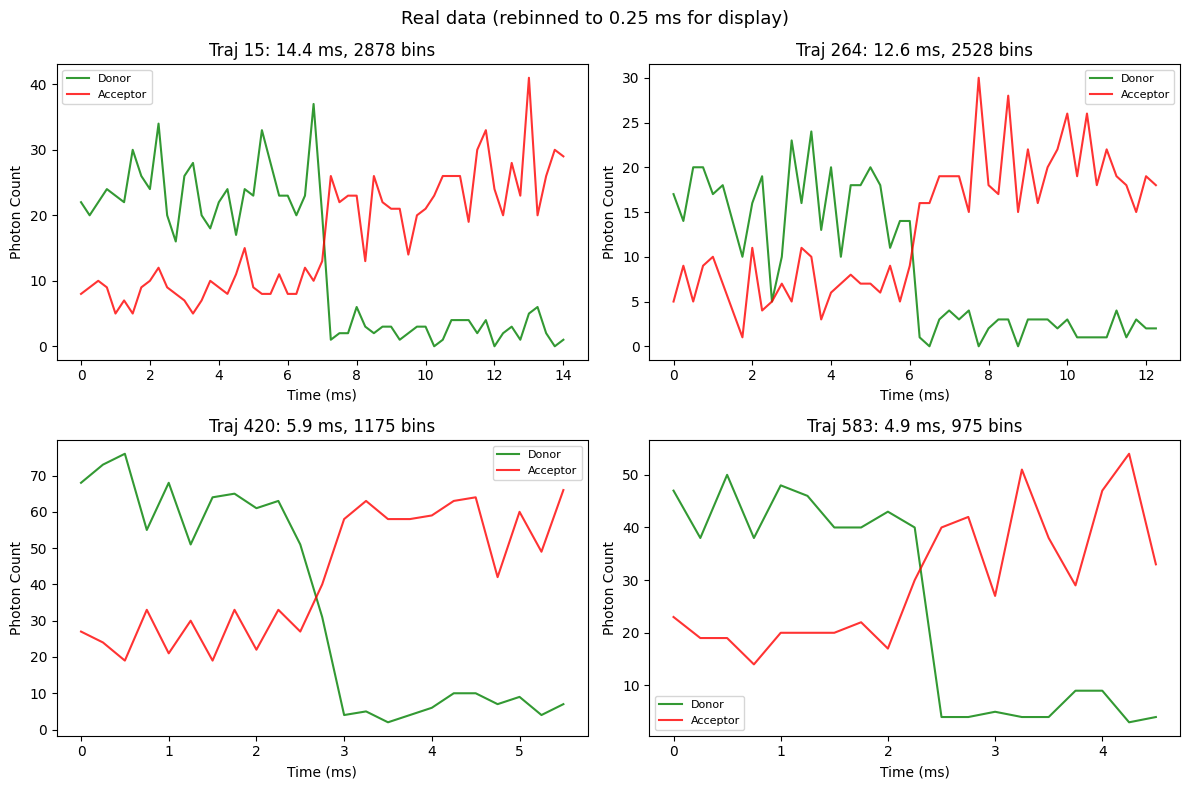

In [29]:
VIS_BIN_WIDTH_MS = 0.25  # coarser bins for visualization
sim_bins_per_vis_bin = max(1, int(round(VIS_BIN_WIDTH_MS / sim_bin_width_ms)))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
show_idx = np.linspace(0, len(obs_tensors) - 1, 4, dtype=int)

for ax, idx in zip(axes.flat, show_idx):
    trace = obs_tensors[idx]
    n_valid = obs_valid[idx]

    # Rebin valid region into coarser visualization bins
    n_vis = n_valid // sim_bins_per_vis_bin
    if n_vis > 0:
        donor = trace[:n_vis * sim_bins_per_vis_bin, 0].reshape(n_vis, sim_bins_per_vis_bin).sum(dim=1).numpy()
        acceptor = trace[:n_vis * sim_bins_per_vis_bin, 1].reshape(n_vis, sim_bins_per_vis_bin).sum(dim=1).numpy()
        t = np.arange(n_vis) * VIS_BIN_WIDTH_MS
        ax.plot(t, donor, color="green", alpha=0.8, label="Donor")
        ax.plot(t, acceptor, color="red", alpha=0.8, label="Acceptor")

    dur_ms = n_valid * sim_bin_width_ms
    ax.set_title(f"Traj {selected_idx[idx]}: {dur_ms:.1f} ms, {n_valid} bins")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Photon Count")
    ax.legend(fontsize=8)

plt.suptitle(f"Real data (rebinned to {VIS_BIN_WIDTH_MS} ms for display)", fontsize=13)
plt.tight_layout()

## Posterior Inference

In [30]:
posterior = DirectPosterior(density_estimator, prior=prior_posterior)
obs = observation.to(device)

samples = posterior.sample(
    (num_posterior_samples,),
    x=obs,
    max_sampling_batch_size=posterior_batch_size,
).cpu()

print(f"Samples shape: {samples.shape}  (expected: [{num_posterior_samples}, {theta_dim}])")

5220it [00:00, 12461.29it/s]                          

Samples shape: torch.Size([5000, 9])  (expected: [5000, 9])


In [31]:
log_prob_batch_size = 30

samples_dev = samples.to(device)
log_probs = []
with torch.no_grad():
    for start in tqdm(range(0, samples_dev.shape[0], log_prob_batch_size), desc="log_prob batches"):
        chunk = samples_dev[start:start + log_prob_batch_size]
        lp = posterior.log_prob(chunk, x=obs)
        log_probs.append(lp.cpu())
log_probs = torch.cat(log_probs)

log_prob batches: 100%|██████████| 167/167 [02:39<00:00,  1.04it/s]


In [32]:
top_k = 1000

top_log_probs, top_idx = torch.topk(log_probs, k=top_k)
top_samples = samples[top_idx]

In [33]:
posterior.set_default_x(obs)
map_estimate = map_with_cached_embedding(
    density_estimator=density_estimator,
    prior=prior_posterior,
    x=obs,  # observation tensor
    num_iter=5000,#map_num_iter,
    num_init_samples=top_samples.shape[0],#map_num_init_samples,
    num_to_optimize=top_samples.shape[0],#top_samples,
    learning_rate=map_learning_rate,
    init_samples=top_samples,
    show_progress_bars=True,
)
print(f"MAP estimate: {map_estimate[0].cpu().numpy().round(3)}")

 Optimizing MAP estimate. Iterations: 5000 / 5000. Performance in iteration 5000: -0.04 (= unnormalized log-prob). Press Ctrl-C to interrupt.MAP estimate: [ 1.982 -8.663  4.926 -4.042  4.896 -4.203  2.585  5.338  6.987]


## Results

/tmp/ipykernel_793337/587263198.py:12: DeprecationWarning: you passed deprecated arguments **kwargs: ['points_offdiag', 'points_colors'], use fig_kwargs instead. We continue calling the deprecated pairplot function
  _ = analysis.pairplot(


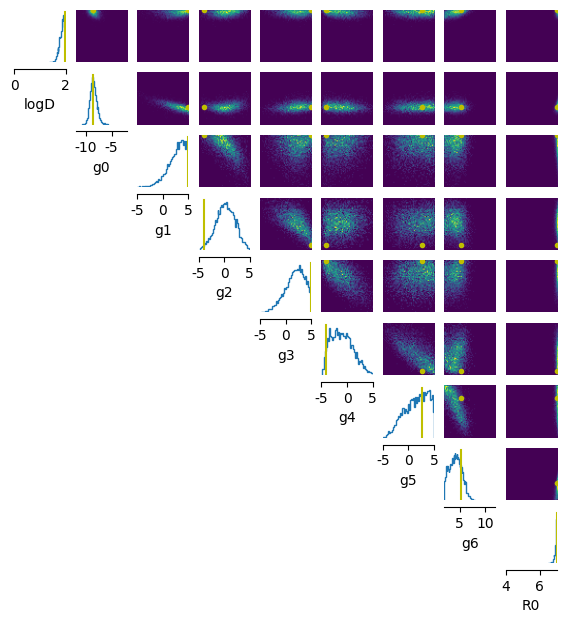

In [35]:
param_labels = ["logD"] + [f"g{i}" for i in range(num_knots)] + ["R0"]

scale = data_cfg.prior.scale
center = list(data_cfg.prior.center) if data_cfg.prior.center is not None else [0.0] * num_knots

limits = (
    [list(data_cfg.prior.logD_lims)]
    + [[c - scale, c + scale] for c in center]
    + [list(data_cfg.prior.R0_lims)]
)

_ = analysis.pairplot(
    samples,
    figsize=(7, 7),
    points=[map_estimate[0].cpu()],
    points_offdiag={"markersize": 6},
    points_colors=["y"],
    limits=limits,
    labels=param_labels,
)

### Free Energy Landscape

Plotting 3400/5000 samples


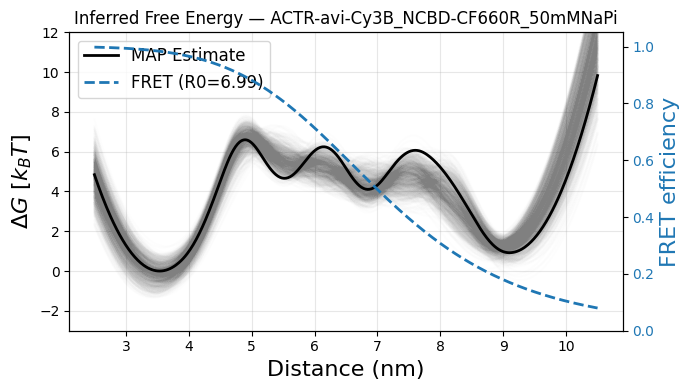

In [36]:
knot_spacing = (data_cfg.simulator.x_max - data_cfg.simulator.x_min) / (num_knots - 1)
x_plot_margin = 0.6 * data_cfg.simulator.num_boundary_knots * knot_spacing
x_eval = np.linspace(data_cfg.simulator.x_min - x_plot_margin,
                     data_cfg.simulator.x_max + x_plot_margin, 500)

# Restrict to the 95% HPD region by posterior log-prob
ci_threshold = torch.quantile(log_probs, 1-0.68)
ci_mask = log_probs >= ci_threshold
samples_ci = samples[ci_mask]
print(f"Plotting {samples_ci.shape[0]}/{samples.shape[0]} samples")

fig, ax1 = plt.subplots(figsize=(7, 4))

# MAP free energy (reference for vertical alignment)
x, y_map = eval_free_energy(params=map_estimate[0].cpu(), x_eval=x_eval)
y_map_shifted = y_map - y_map.min()

# Posterior free energy samples within 95% HPD (aligned to MAP)
n_plot = min(1000, samples_ci.shape[0])
for i in range(n_plot):
    x, y = eval_free_energy(params=samples_ci[i], x_eval=x_eval)
    offset = np.mean(y_map_shifted - y)
    ax1.plot(x, y + offset, color="gray", alpha=0.01)

# MAP
ax1.plot(x, y_map_shifted, color="black", lw=2, label="MAP Estimate")

ax1.set_xlabel("Distance (nm)", fontsize=16)
ax1.set_ylabel(r"$\Delta G\ [k_BT]$", fontsize=16)
ax1.set_ylim(-3, 12)
ax1.grid(alpha=0.3)

# FRET efficiency on secondary axis (use MAP R0)
ax2 = ax1.twinx()
R0_map = float(map_estimate[0][-1].cpu())
r = np.clip(x_eval, 1e-9, None)
E = 1.0 / (1.0 + (r / R0_map) ** 6)
ax2.plot(x_eval, E, color="tab:blue", linestyle="--", linewidth=2, label=f"FRET (R0={R0_map:.2f})")
ax2.set_ylabel("FRET efficiency", color="tab:blue", fontsize=16)
ax2.set_ylim(0, 1.05)
ax2.tick_params(axis="y", labelcolor="tab:blue")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=12, loc="best")
ax1.set_title(f"Inferred Free Energy — {condition_name}", fontsize=12)
plt.tight_layout()

### Diffusion Coefficient

In [ ]:
logD_samples = samples[:, 0].numpy()
D_samples = 10 ** logD_samples  # nm^2/ms

D_median = np.median(D_samples)
D_lo, D_hi = np.percentile(D_samples, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# logD posterior
axes[0].hist(logD_samples, bins=50, edgecolor="black", alpha=0.7, color="steelblue")
axes[0].axvline(float(map_estimate[0][0].cpu()), color="orange", ls="--", lw=2, label="MAP")
axes[0].set_xlabel("logD", fontsize=14)
axes[0].set_ylabel("Count", fontsize=14)
axes[0].set_title("Posterior: logD")
axes[0].legend()

# D posterior
axes[1].hist(D_samples, bins=50, edgecolor="black", alpha=0.7, color="teal")
axes[1].axvline(D_median, color="black", ls="--", lw=1.5, label=f"Median = {D_median:.3f}")
axes[1].axvspan(D_lo, D_hi, alpha=0.15, color="gray", label=f"95% CI = [{D_lo:.3f}, {D_hi:.3f}]")
axes[1].set_xlabel(r"$D$ (nm$^2$/ms)", fontsize=14)
axes[1].set_ylabel("Count", fontsize=14)
axes[1].set_title("Posterior: Diffusion Coefficient")
axes[1].legend(fontsize=10)

plt.tight_layout()

print(f"Diffusion coefficient D (nm^2/ms):")
print(f"  Median: {D_median:.4f}")
print(f"  95% CI: [{D_lo:.4f}, {D_hi:.4f}]")
print(f"  MAP:    {10**float(map_estimate[0][0].cpu().item()):.4f}")

In [ ]:
R0_samples = samples[:, -1].numpy()  # R0 is the last parameter, no log transform

R0_median = np.median(R0_samples)
R0_lo, R0_hi = np.percentile(R0_samples, [2.5, 97.5])
R0_map = float(map_estimate[0][-1].cpu())

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(R0_samples, bins=50, edgecolor="black", alpha=0.7, color="mediumpurple")
ax.axvline(R0_map, color="orange", ls="--", lw=2, label=f"MAP = {R0_map:.3f}")
ax.axvline(R0_median, color="black", ls="--", lw=1.5, label=f"Median = {R0_median:.3f}")
ax.axvspan(R0_lo, R0_hi, alpha=0.15, color="gray", label=f"95% CI = [{R0_lo:.3f}, {R0_hi:.3f}]")

ax.set_xlabel(r"$R_0$ (nm)", fontsize=14)
ax.set_ylabel("Count", fontsize=14)
ax.set_title("Posterior: $R_0$")
ax.legend(fontsize=10)

plt.tight_layout()

print("R0 (nm):")
print(f"  Median: {R0_median:.4f}")
print(f"  95% CI: [{R0_lo:.4f}, {R0_hi:.4f}]")
print(f"  MAP:    {R0_map:.4f}")


## Pooled FRET-efficiency PPC

Compare the pooled distribution of $E(t) = n_R / (n_R + n_G)$ between the
real observation and a MAP-predictive simulation (with photophysics
nuisances drawn from their prior).  Model-free, shot-noise-tolerant check
that the inferred free energy reproduces the basin populations.


In [ ]:
import os
from multiprocessing import Pool
from simulator import binding_simulator_wrapper_from_config
from priors import generate_split_priors_from_config


_fret_simulator = binding_simulator_wrapper_from_config(data_cfg_path)
fret_prior = generate_fret_prior_from_config(data_cfg_path, device="cpu")
_, _, inferred_idx, _ = generate_split_priors_from_config(data_cfg_path, device="cpu")


def _init_worker():
    np.random.seed(os.getpid())


def _trace_to_E(n_G, n_R, k_smooth):
    total = n_G + n_R
    with np.errstate(invalid="ignore", divide="ignore"):
        E = np.where(total > 0, n_R / np.maximum(total, 1e-12), np.nan)
    if k_smooth > 1:
        valid = np.isfinite(E)
        filled = np.where(valid, E, 0.0)
        counts = np.convolve(valid.astype(float), np.ones(k_smooth), mode="same")
        E = np.convolve(filled, np.ones(k_smooth), mode="same") / np.maximum(counts, 1.0)
        E[counts == 0] = np.nan
    return E


k_smooth = 200 #max(1, int(data_cfg.simulator.binding.k_persist) // 2)
num_ppc_sim = 2000

# MAP-predictive simulation: keep MAP for [logD, g_0..g_{n-1}, R0] and draw
# nuisances (kD, photophysics) from their prior since we have no ground truth.
map_7 = map_estimate[0].cpu()
params_list = []
for _ in range(num_ppc_sim):
    params_16 = fret_prior.sample((1,)).squeeze().clone()
    params_16[inferred_idx] = map_7
    params_list.append(params_16)

with Pool(processes=24, initializer=_init_worker) as pool:
    raw_sim = pool.map(_fret_simulator, params_list)

sim_counts = []
for r in raw_sim:
    if r is None:
        continue
    trace, length = r
    if isinstance(trace, torch.Tensor):
        trace = trace.cpu().numpy()
    sim_counts.append((trace[:length, 0], trace[:length, 1]))
print(f"MAP-predictive: {len(sim_counts)}/{num_ppc_sim} simulations succeeded")

E_real = np.concatenate([
    _trace_to_E(obs_tensors[i][:obs_valid[i], 0].numpy(),
                obs_tensors[i][:obs_valid[i], 1].numpy(), k_smooth)
    for i in range(len(obs_tensors))
])
E_sim = np.concatenate([
    _trace_to_E(donor, acceptor, k_smooth)
    for donor, acceptor in sim_counts
])
E_real = E_real[np.isfinite(E_real)]
E_sim  = E_sim[np.isfinite(E_sim)]

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, 1, 81)
ax.hist(E_real, bins=bins, density=True, histtype="step", color="tab:blue",
        linewidth=2, label=f"Real  N={E_real.size}")
ax.hist(E_sim,  bins=bins, density=True, histtype="step", color="black",
        linewidth=2, label=f"MAP   N={E_sim.size}")
ax.set_xlabel("E  (FRET efficiency)", fontsize=14)
ax.set_ylabel("density", fontsize=14)
ax.set_title(f"Pooled FRET-efficiency PPC — {condition_name}  (k_smooth={k_smooth})")
ax.legend(fontsize=11)
ax.grid()
plt.tight_layout()
